In [6]:
import LightPipes
from LightPipes import GaussBeam, Begin, Intensity, Phase, GaussLaguerre
import matplotlib.pyplot as plt

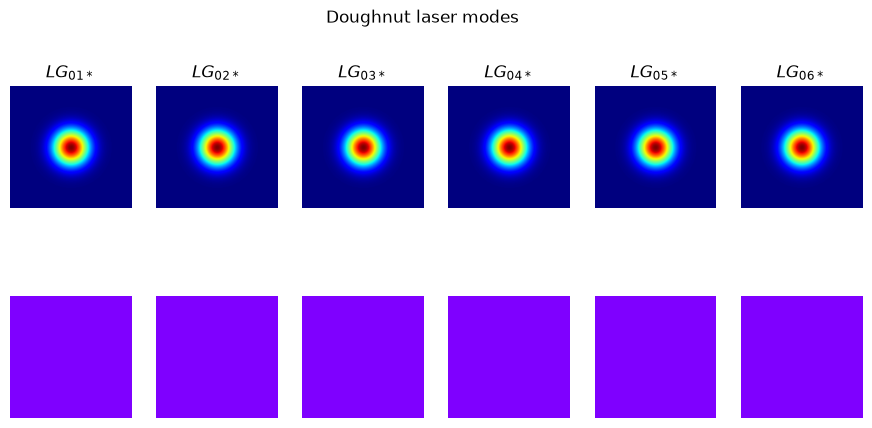

In [8]:
wavelength = 500e-9
size = 15e-3
N = 200
w0=3e-3
i=0

m_max=6
fig, axs = plt.subplots(nrows=2, ncols=m_max,figsize=(11.0,5.0))
s=r'Doughnut laser modes'
fig.suptitle(s)
F=Begin(size,wavelength,N)
n=0
for m in range(1,m_max+1):
    #F=GaussBeam(F, w0, doughnut=True, n=n, m=m)
    F = GaussLaguerre(F, 3e-3)
    I=Intensity(0,F)
    Phi=Phase(F)
    s=f'$LG_{n}$' + f'$_{m}$' + '$_*$'
    axs[0][m-1].imshow(I,cmap='jet'); axs[0][m-1].axis('off'); axs[0][m-1].set_title(s)
    axs[1][m-1].imshow(Phi,cmap='rainbow'); axs[1][m-1].axis('off');
plt.show()

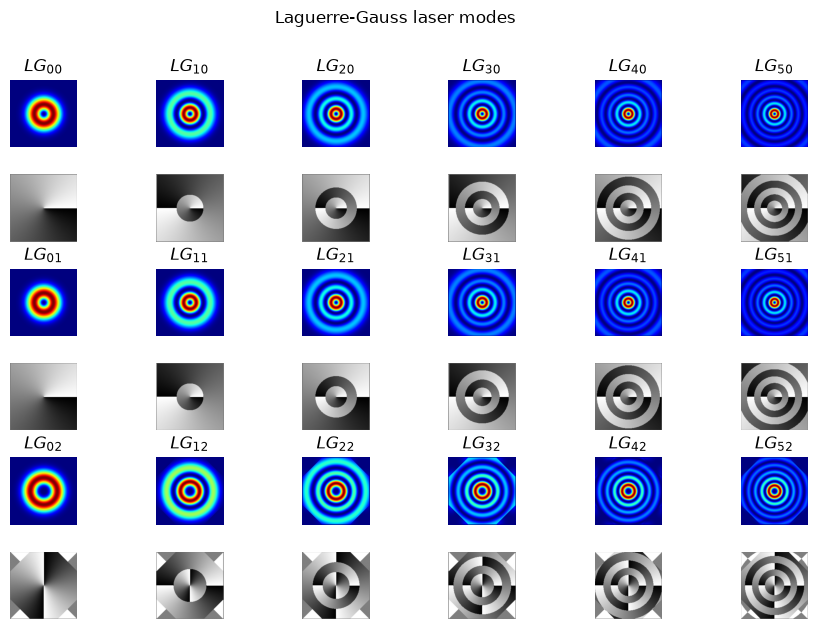

In [14]:
from LightPipes import *
import matplotlib.pyplot as plt
if LPversion < "2.0.0":
    print(r'You need to upgrade LightPipes to run this script.' + '\n'+r'Type at a terminal prompt: $ pip install --upgrade LightPipes')
    exit(1)

wavelength = 500*nm
size = 15*mm
N = 200
w0=3*mm
i=0
LG=True

n_max=6;m_max=6
fig, axs = plt.subplots(nrows=m_max, ncols=n_max,figsize=(11.0,7.0))
if LG:
    s=r'Laguerre-Gauss laser modes'
else:
    s=r'Hermite-Gauss laser modes'

fig.suptitle(s)
fig.subplots_adjust(hspace=0.4)

F=Begin(size,wavelength,N)
for m in range(int(m_max/2)):
    for n in range(n_max):
        F=GaussBeam(F, w0, LG=LG, n=n, m=m, doughnut=True)
        I=Intensity(0,F)
        Phi=Phase(F)
        if LG:
            s=f'$LG_{n}$' + f'$_{m}$'
        else:
            s=f'$HG_{n}$' + f'$_{m}$'
        axs[m+i][n].imshow(I,cmap='jet'); axs[m+i][n].axis('off'); axs[m+i][n].set_title(s)
        axs[m+1+i][n].imshow(Phi,cmap='gray'); axs[m+1+i][n].axis('off')
    i+=1

plt.show()

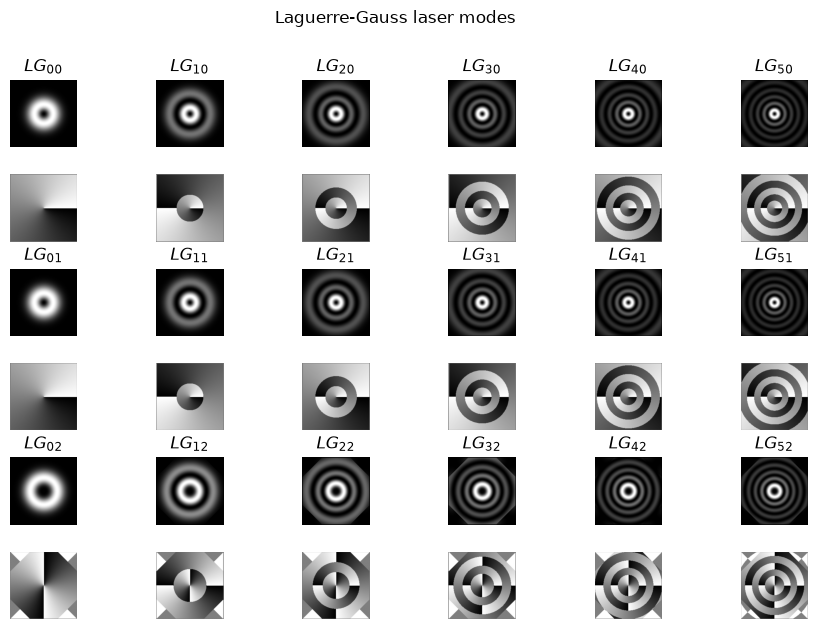

In [ ]:
from LightPipes import *
import matplotlib.pyplot as plt

wavelength = 532*nm
size = 15*mm
N = 200
w0=3*mm
i=0
LG=True

n_max=6;m_max=6
fig, axs = plt.subplots(nrows=m_max, ncols=n_max,figsize=(11.0,7.0))
if LG:
    s=r'Laguerre-Gauss laser modes'
else:
    s=r'Hermite-Gauss laser modes'

fig.suptitle(s)
fig.subplots_adjust(hspace=0.4)

F=Begin(size,wavelength,N)
for m in range(int(m_max/2)):
    for n in range(n_max):
        F=GaussBeam(F, w0, LG=LG, n=n, m=m)
        I=Intensity(0,F)
        Phi=Phase(F)
        if LG:
            s=f'$LG_{n}$' + f'$_{m}$'
        else:
            s=f'$HG_{n}$' + f'$_{m}$'
        axs[m+i][n].imshow(I,cmap='gray'); axs[m+i][n].axis('off'); axs[m+i][n].set_title(s)
        axs[m+1+i][n].imshow(Phi,cmap='gray'); axs[m+1+i][n].axis('off')
    i+=1

plt.show()

In [5]:


from diffractio import sp, nm, plt, np, mm, degrees, um
from diffractio.scalar_fields_XY import Scalar_field_XY
from diffractio.scalar_sources_XY import Scalar_source_XY
from diffractio.scalar_masks_XY import Scalar_mask_XY
import numpy as np

/home/pedro/Dev/Playground/util/jupiter/phase_masks/venv/lib/python3.12/site-packages/diffractio/scalar_fields_XY.py:2485: SyntaxWarning: invalid escape sequence '\m'
  xlabel="r$x  (\mu m)$",
/home/pedro/Dev/Playground/util/jupiter/phase_masks/venv/lib/python3.12/site-packages/diffractio/scalar_fields_XY.py:2486: SyntaxWarning: invalid escape sequence '\m'
  ylabel="r$y  (\mu m)$",
/home/pedro/Dev/Playground/util/jupiter/phase_masks/venv/lib/python3.12/site-packages/diffractio/utils_optics.py:920: SyntaxWarning: invalid escape sequence '\p'
  axs[0].plot(kx, np.abs(t_TM), "r", label="r$t_{\parallel, TM}$")
/home/pedro/Dev/Playground/util/jupiter/phase_masks/venv/lib/python3.12/site-packages/diffractio/utils_optics.py:922: SyntaxWarning: invalid escape sequence '\p'
  axs[0].plot(kx, np.abs(t_TE), "b", label="r$t_{\perp, TE}$")
/home/pedro/Dev/Playground/util/jupiter/phase_masks/venv/lib/python3.12/site-packages/diffractio/utils_optics.py:924: SyntaxWarning: invalid escape sequence '\p

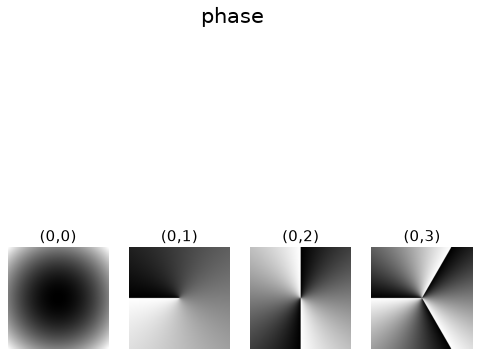

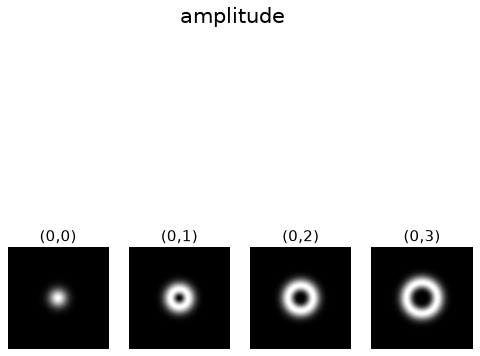

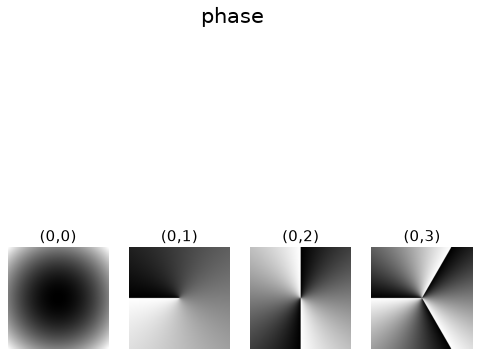

In [9]:
N = 0
K = 3

x0 = np.linspace(-1*mm, 1*mm, 512)
y0 = np.linspace(-1*mm, 1*mm, 512)
wavelength = 0.6238*um

u = Scalar_source_XY(x=x0, y=y0, wavelength=wavelength)

ID1 = plt.figure(figsize=(8, 8))
plt.suptitle("amplitude", fontsize=20)
ID2 = plt.figure(figsize=(8, 8))
plt.suptitle("phase", fontsize=20)

for n in range(N + 1):
    for k in range(K + 1):

        u.laguerre_beam(A=1,
                        n=n,
                        l=k,
                        r0=(0*um, 0*um),
                        w0=250*um,
                        z0=0,
                        z=0.01*um)

        title = "(%d,%d)" % (n, k)
        plt.figure(ID1.number)
        plt.subplot(N + 1, K + 1, (N + 1) * (k) + n + 1)
        plt.axis('off')
        plt.title(title, fontsize=14)
        h1 = plt.imshow(np.abs(u.u)**2)
        h1.set_cmap("gray")

        plt.figure(ID2.number)
        plt.subplot(N + 1, K + 1, (N + 1) * (k) + n + 1)
        plt.axis('off')
        plt.title(title, fontsize=14)
        h2 = plt.imshow(np.angle(u.u))
        h2.set_cmap("gray")

plt.figure(ID1.number)
plt.figure(ID2.number)

In [13]:
from diffractio import sp, nm, plt, np, mm, degrees, um
from diffractio.scalar_fields_XY import Scalar_field_XY
from diffractio.scalar_sources_XY import Scalar_source_XY
from diffractio.scalar_masks_XY import Scalar_mask_XY

wavelength = 0.5 * um
x0 = np.linspace(-0.25 * mm, 0.25 * mm, 512)
y0 = np.linspace(-0.25 * mm, 0.25 * mm, 512)

u0 = Scalar_source_XY(x=x0, y=y0, wavelength=wavelength, info="u0")

### There are many methods that can be used to generate a light source:

    - plane_wave: Generates a plane wave with a given direction and amplitude

    - gauss_beam: Generates a gauss beam with a given amplitude, direction, beam-waist and position of beam-waist.

    - spherical_wave: Generates a spherical wave.

    - vortex_beam: Generates a vortex beam.

    - laguerre_beam: Generates a Laguerre beam.
 
    - hermite_gauss_beam: Generates a Hermite-Gauss beam.
 
    - zernike_beam: Generates aberrated beams using Zernike functions.
 
    - bessel_beam: Generates a bessel beam.
 
    - plane_waves_several_inclined: Generate several plane waves with different incident angles.
 
    - plane_waves_dict: Generate several plane waves with parameters defined in a dictionary.
 
    - gauss_beams_several_parallel: Generates a number of parallel gauss beam at different positions.
 
    - gauss_beams_several_inclined: Generates a number of gauss beams all placed at the same position but with different incidence angles.



In [19]:
u0.vortex_beam(A=1, r0=(0 * um, 0 * um), w0=100 * um, m=3)
print(u0)

Scalar_source_XY
 - x:  (512,),   y:  (512,),   u:  (512, 512)
 - xmin:       -250.00 um,  xmax:      250.00 um,  Dx:   0.98 um
 - ymin:       -250.00 um,  ymax:      250.00 um,  Dy:   0.98 um
 - Imin:       0.00,     Imax:      1.00
 - phase_min:  -180.00 deg, phase_max: 180.00 deg
 - wavelength: 0.50 um
 - date:       2026-10-29_15_39_11
 - info:       u0



((<matplotlib.image.AxesImage at 0x7a62da67cb90>,
  <matplotlib.image.AxesImage at 0x7a62da673770>),
 None,
 None)

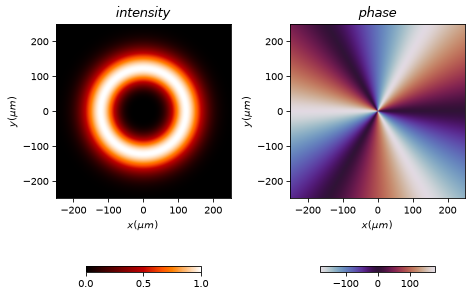

In [17]:
u0.draw(kind="field")